# Renewable Energy Generation & Weather Pattern Analytics Using Python

**Student:** Aarya Saxena  
**Roll No.:** 24202803  
**Course:** Bachelor of Science (B.Sc.)  
**College:** Government P.G. College, Dholpur  
**University:** Maharaja Surajmal Brij University  
**Program:** IBM SkillsBuild Data Analytics with AI Academic Internship (BharatCares in association with AICTE)

---

## Project brief
This notebook studies daily solar-generation patterns across four illustrative solar sites using weather, plant-operation and calendar variables. It performs data-quality checks, exploratory analysis, visualisation, and a machine-learning demonstration to estimate daily solar generation.

> **Data integrity note:** The included CSV is a **synthetic educational dataset** created for this project. It is not official plant telemetry, government monitoring data, or a real-world survey. Numeric findings describe this dataset only and should not be used as forecasts for actual energy assets.

### Research questions
1. How do seasonal weather patterns relate to daily solar generation?
2. How do sites differ in total and average daily generation?
3. Which recorded variables are most associated with output?
4. How accurately can a model estimate generation on a later time period?

## 1. Import libraries and configure the notebook
The code below uses widely used Python data-science libraries. Install the packages in `requirements.txt` if your environment does not already contain them.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
print("Libraries loaded successfully.")

Libraries loaded successfully.


## 2. Load the dataset
Keep `renewable_energy_weather_dataset.csv` in the same folder as this notebook. If your notebook is opened from another working directory, update `DATA_PATH` to the correct CSV location.

In [2]:
DATA_PATH = Path("renewable_energy_weather_dataset.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Dataset not found. Place renewable_energy_weather_dataset.csv next to this notebook "
        "or update DATA_PATH to its location."
    )

df = pd.read_csv(DATA_PATH)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
print(f"Dataset shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Date range: {df['date'].min().date()} to {df['date'].max().date()}")
print(f"Sites represented: {df['site'].nunique()}")
display(df.head(8))

Dataset shape: 4,384 rows × 15 columns
Date range: 2022-01-01 to 2024-12-31
Sites represented: 4


,date,site,district,installed_capacity_mw,temperature_c,solar_irradiance_kwh_m2_day,cloud_cover_pct,humidity_pct,wind_speed_m_s,rainfall_mm,panel_cleanliness_index,outage_hours,plant_availability_pct,grid_demand_mwh,solar_generation_mwh
0,2022-01-01,Dholpur Solar Park,Dholpur,20.0,17.86,4.612,21.7,52.2,2.83,0.0,0.846,0.02,98.85,459.96,56.474
1,2022-01-02,Dholpur Solar Park,Dholpur,20.0,15.56,4.835,13.2,51.0,0.49,0.0,0.845,0.03,99.85,379.25,61.144
2,2022-01-03,Dholpur Solar Park,Dholpur,20.0,20.82,4.480,29.3,53.7,1.78,0.0,0.841,0.04,98.92,379.73,56.823
3,2022-01-04,Dholpur Solar Park,Dholpur,20.0,22.62,4.813,8.9,56.1,1.70,0.0,0.835,0.01,100.00,366.38,63.389
4,2022-01-05,Dholpur Solar Park,Dholpur,20.0,17.25,4.008,30.9,53.4,0.58,0.0,0.830,0.03,99.75,410.33,50.357
5,2022-01-06,Dholpur Solar Park,Dholpur,20.0,20.35,4.729,7.0,60.2,5.14,0.0,0.826,0.04,100.00,432.60,60.253
6,2022-01-07,Dholpur Solar Park,Dholpur,20.0,16.69,4.095,25.8,55.1,2.32,0.0,0.824,0.02,100.00,465.69,52.790
7,2022-01-08,Dholpur Solar Park,Dholpur,20.0,18.62,4.203,6.2,46.8,1.63,0.0,0.822,0.27,99.68,473.86,51.173


## 3. Understand the columns
The primary outcome is `solar_generation_mwh`. Weather and operational variables are explanatory inputs. The generation values are generated by a transparent synthetic process, so the model is a demonstration of analytical workflow, not validation on measured energy production.

In [3]:
data_dictionary = pd.DataFrame([
    ("date", "Daily observation date", "Date"),
    ("site", "Illustrative solar installation name", "Category"),
    ("district", "District label used in the scenario", "Category"),
    ("installed_capacity_mw", "Illustrative installed capacity", "MW"),
    ("temperature_c", "Daily temperature value", "°C"),
    ("solar_irradiance_kwh_m2_day", "Daily solar resource indicator", "kWh/m²/day"),
    ("cloud_cover_pct", "Estimated cloud-cover percentage", "%"),
    ("humidity_pct", "Relative humidity indicator", "%"),
    ("wind_speed_m_s", "Wind speed indicator", "m/s"),
    ("rainfall_mm", "Daily rainfall indicator", "mm"),
    ("panel_cleanliness_index", "Relative panel cleanliness (1 = cleanest)", "Index"),
    ("outage_hours", "Hours unavailable during the day", "Hours"),
    ("plant_availability_pct", "Illustrative operating availability", "%"),
    ("grid_demand_mwh", "Illustrative daily grid-demand indicator", "MWh"),
    ("solar_generation_mwh", "Synthetic daily solar energy output (target)", "MWh/day"),
], columns=["Column", "Meaning", "Unit / type"])
display(data_dictionary)

,Column,Meaning,Unit / type
0,date,Daily observation date,Date
1,site,Illustrative solar installation name,Category
2,district,District label used in the scenario,Category
3,installed_capacity_mw,Illustrative installed capacity,MW
4,temperature_c,Daily temperature value,°C
5,solar_irradiance_kwh_m2_day,Daily solar resource indicator,kWh/m²/day
6,cloud_cover_pct,Estimated cloud-cover percentage,%
7,humidity_pct,Relative humidity indicator,%
8,wind_speed_m_s,Wind speed indicator,m/s
9,rainfall_mm,Daily rainfall indicator,mm


## 4. Data-quality and consistency checks
We check missing values, duplicated rows, types and plausible ranges before analysing the data. The notebook deliberately reports quality issues before any transformation rather than silently ignoring them.

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})
display(quality)
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Invalid dates:", int(df["date"].isna().sum()))
print("Negative generation values:", int((df["solar_generation_mwh"] < 0).sum()))
print("Outage values beyond 24 hours:", int((df["outage_hours"] > 24).sum()))

# This dataset is expected to be complete. If using a different file, investigate these counts.
assert df["date"].notna().all(), "Review invalid dates before proceeding."
assert (df["solar_generation_mwh"] >= 0).all(), "Review negative output values."
assert df["site"].notna().all(), "Review missing site labels."
print("Core validation checks passed.")

,dtype,missing_values,missing_pct,unique_values
date,datetime64[ns],0,0.0,1096
site,object,0,0.0,4
district,object,0,0.0,4
installed_capacity_mw,float64,0,0.0,4
temperature_c,float64,0,0.0,2241
solar_irradiance_kwh_m2_day,float64,0,0.0,2812
cloud_cover_pct,float64,0,0.0,780
humidity_pct,float64,0,0.0,803
wind_speed_m_s,float64,0,0.0,738
rainfall_mm,float64,0,0.0,896


Exact duplicate rows: 0
Invalid dates: 0
Negative generation values: 0
Outage values beyond 24 hours: 0
Core validation checks passed.


## 5. Feature engineering and summary metrics
Calendar fields make seasonal patterns easier to compare. Season definitions are kept explicit so they can be changed to match a different study context.

In [5]:
season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Summer", 4: "Summer", 5: "Summer",
    6: "Monsoon", 7: "Monsoon", 8: "Monsoon", 9: "Monsoon",
    10: "Post-monsoon", 11: "Post-monsoon"
}
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_year"] = df["date"].dt.dayofyear
df["season"] = df["month"].map(season_map)

kpis = pd.DataFrame({
    "Measure": ["Rows", "Sites", "Mean daily generation (MWh)", "Median daily generation (MWh)",
                "Total generated energy (MWh)", "Mean daily solar resource (kWh/m²/day)",
                "Mean plant availability (%)", "Mean cleanliness index"],
    "Value": [len(df), df["site"].nunique(), df["solar_generation_mwh"].mean(),
              df["solar_generation_mwh"].median(), df["solar_generation_mwh"].sum(),
              df["solar_irradiance_kwh_m2_day"].mean(), df["plant_availability_pct"].mean(),
              df["panel_cleanliness_index"].mean()]
})
kpis["Value"] = kpis["Value"].map(lambda x: f"{x:,.2f}" if isinstance(x, (float, np.floating)) else f"{x:,}")
display(kpis)
print("Highest cumulative generation:", df.groupby("site")["solar_generation_mwh"].sum().idxmax())

,Measure,Value
0,Rows,"4,384.00"
1,Sites,4.00
2,Mean daily generation (MWh),72.09
3,Median daily generation (MWh),68.35
4,Total generated energy (MWh),"316,053.24"
5,Mean daily solar resource (kWh/m²/day),5.14
6,Mean plant availability (%),99.42
7,Mean cleanliness index,0.80


Highest cumulative generation: Jodhpur Sun Array


## 6. Site-level performance comparison
Capacity differences matter when comparing sites. We therefore inspect total output and mean daily output together and avoid interpreting totals as efficiency rankings without capacity-normalised metrics.

,site,district,installed_capacity_mw,observations,total_generation_mwh,mean_daily_generation_mwh,mean_irradiance,mean_availability_pct,capacity_normalised_output
2,Jodhpur Sun Array,Jodhpur,30.0,1096,107129.36,97.75,5.20,99.42,3.26
1,Jaipur Solar Field,Jaipur,24.0,1096,81375.39,74.25,5.16,99.40,3.09
0,Dholpur Solar Park,Dholpur,20.0,1096,71113.19,64.88,5.12,99.42,3.24
3,Udaipur Solar Station,Udaipur,18.0,1096,56435.31,51.49,5.08,99.44,2.86


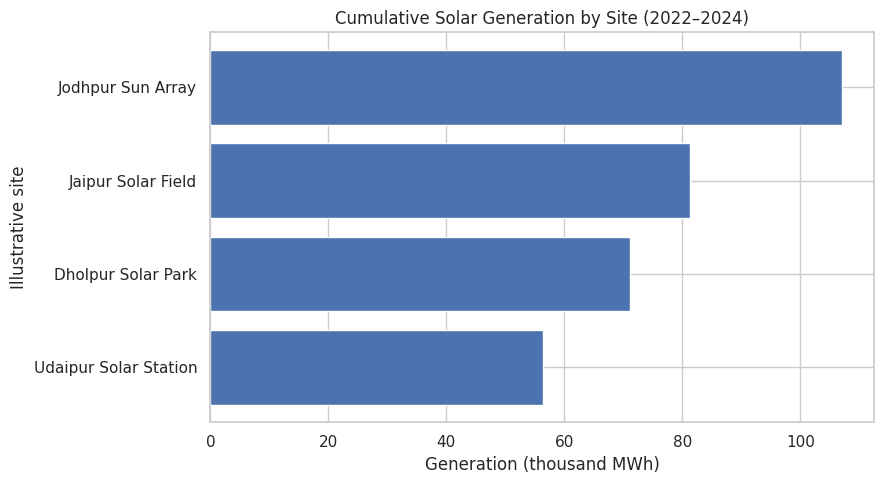

In [6]:
site_summary = (df.groupby(["site", "district", "installed_capacity_mw"], as_index=False)
    .agg(observations=("date", "size"),
         total_generation_mwh=("solar_generation_mwh", "sum"),
         mean_daily_generation_mwh=("solar_generation_mwh", "mean"),
         mean_irradiance=("solar_irradiance_kwh_m2_day", "mean"),
         mean_availability_pct=("plant_availability_pct", "mean")))
site_summary["capacity_normalised_output"] = site_summary["mean_daily_generation_mwh"] / site_summary["installed_capacity_mw"]
display(site_summary.sort_values("total_generation_mwh", ascending=False).round(2))

site_plot = site_summary.sort_values("total_generation_mwh", ascending=True)
plt.figure(figsize=(9, 5))
plt.barh(site_plot["site"], site_plot["total_generation_mwh"] / 1000)
plt.title("Cumulative Solar Generation by Site (2022–2024)")
plt.xlabel("Generation (thousand MWh)")
plt.ylabel("Illustrative site")
plt.tight_layout()
plt.show()

## 7. Seasonal generation patterns
Seasonal averages can reflect available sunlight, cloud cover, temperature-related performance, and maintenance effects. They describe the constructed dataset only and should not be taken as a climatological finding for Rajasthan.

,season,avg_generation_mwh,avg_irradiance,avg_temperature_c,avg_cloud_cover_pct
0,Winter,68.14,4.70,18.74,19.06
1,Summer,92.15,6.61,33.42,15.12
2,Monsoon,59.36,4.28,32.96,45.13
3,Post-monsoon,73.15,5.31,26.26,16.92


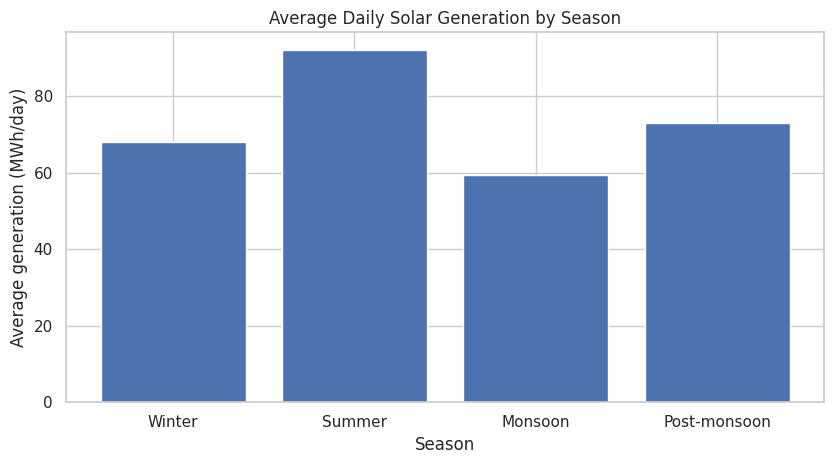

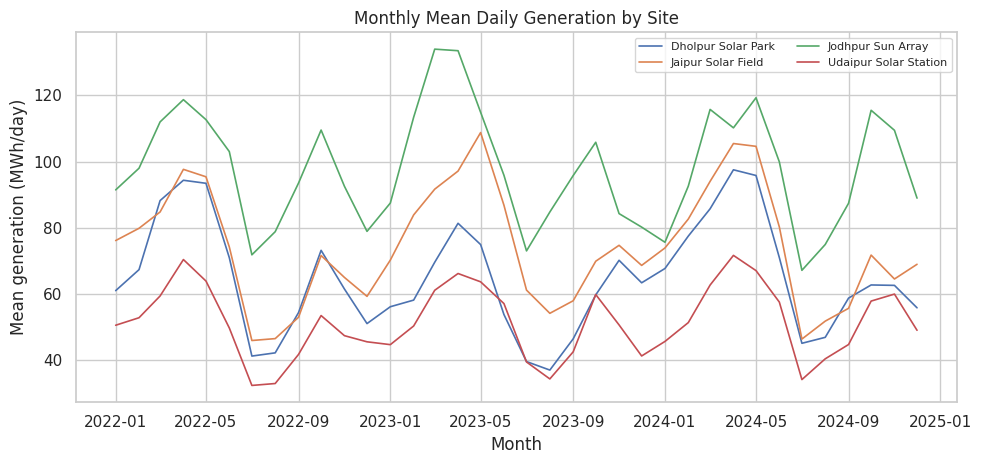

In [7]:
season_order = ["Winter", "Summer", "Monsoon", "Post-monsoon"]
season_summary = (df.groupby("season", observed=False)
    .agg(avg_generation_mwh=("solar_generation_mwh", "mean"),
         avg_irradiance=("solar_irradiance_kwh_m2_day", "mean"),
         avg_temperature_c=("temperature_c", "mean"),
         avg_cloud_cover_pct=("cloud_cover_pct", "mean"))
    .reindex(season_order).reset_index())
display(season_summary.round(2))
plt.figure(figsize=(8.5, 4.8))
plt.bar(season_summary["season"], season_summary["avg_generation_mwh"])
plt.title("Average Daily Solar Generation by Season")
plt.xlabel("Season")
plt.ylabel("Average generation (MWh/day)")
plt.tight_layout()
plt.show()

monthly = df.groupby(["year", "month"], as_index=False).agg(
    avg_generation_mwh=("solar_generation_mwh", "mean"),
    avg_irradiance=("solar_irradiance_kwh_m2_day", "mean"))
monthly["month_start"] = pd.to_datetime(monthly["year"].astype(str) + "-" + monthly["month"].astype(str) + "-01")
plt.figure(figsize=(10, 4.8))
for site, group in df.groupby("site"):
    site_month = group.groupby(group["date"].dt.to_period("M"))["solar_generation_mwh"].mean()
    plt.plot(site_month.index.to_timestamp(), site_month.values, label=site, linewidth=1.2)
plt.title("Monthly Mean Daily Generation by Site")
plt.xlabel("Month")
plt.ylabel("Mean generation (MWh/day)")
plt.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## 8. Relationships between weather and output
Correlation is a measure of linear association, not proof of causation. Capacity and site differences can influence the correlations; operational context should accompany any interpretation.

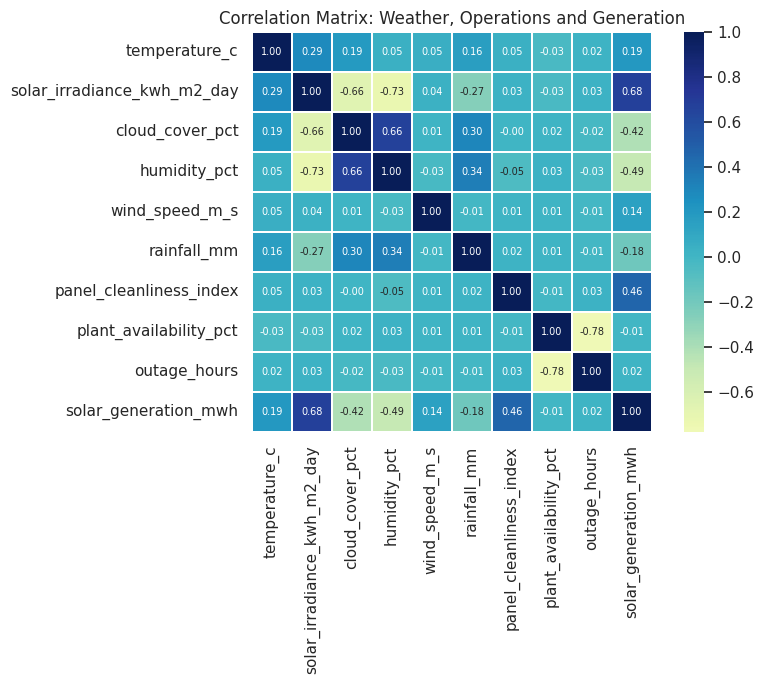

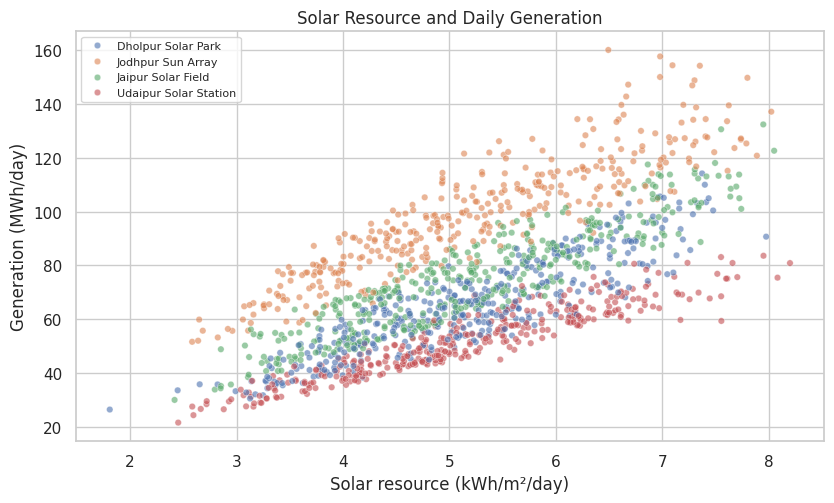

Correlation between solar resource and generation: 0.679


In [8]:
analysis_cols = ["temperature_c", "solar_irradiance_kwh_m2_day", "cloud_cover_pct", "humidity_pct",
                 "wind_speed_m_s", "rainfall_mm", "panel_cleanliness_index", "plant_availability_pct",
                 "outage_hours", "solar_generation_mwh"]
corr = df[analysis_cols].corr(numeric_only=True)
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="YlGnBu", center=0, square=True,
            linewidths=0.3, annot_kws={"fontsize": 7})
plt.title("Correlation Matrix: Weather, Operations and Generation")
plt.tight_layout()
plt.show()

sample = df.sample(min(1500, len(df)), random_state=42)
plt.figure(figsize=(8.5, 5.2))
sns.scatterplot(data=sample, x="solar_irradiance_kwh_m2_day", y="solar_generation_mwh", hue="site", alpha=.6, s=22)
plt.title("Solar Resource and Daily Generation")
plt.xlabel("Solar resource (kWh/m²/day)")
plt.ylabel("Generation (MWh/day)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Correlation between solar resource and generation:", round(df["solar_irradiance_kwh_m2_day"].corr(df["solar_generation_mwh"]), 3))

## 9. Predictive modelling design
To better represent forecasting into the future, the model is trained on observations before **1 May 2024** and evaluated on later observations. Categorical site labels are one-hot encoded; numeric missing values are imputed by a pipeline. The same date cut-off and predictors are used for both candidate models.

In [9]:
target = "solar_generation_mwh"
features = [
    "site", "district", "installed_capacity_mw", "temperature_c", "solar_irradiance_kwh_m2_day",
    "cloud_cover_pct", "humidity_pct", "wind_speed_m_s", "rainfall_mm", "panel_cleanliness_index",
    "outage_hours", "plant_availability_pct", "month", "day_of_year"
]
train_mask = df["date"] < pd.Timestamp("2024-05-01")
X_train, y_train = df.loc[train_mask, features], df.loc[train_mask, target]
X_test, y_test = df.loc[~train_mask, features], df.loc[~train_mask, target]

categorical_features = ["site", "district"]
numeric_features = [column for column in features if column not in categorical_features]
preprocess = ColumnTransformer(transformers=[
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median"))]), numeric_features),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
])

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=180, min_samples_leaf=2, random_state=42, n_jobs=-1)
}
trained_models = {}
results = []
predictions = {}
for name, estimator in models.items():
    pipe = Pipeline([("preprocess", preprocess), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    trained_models[name] = pipe
    predictions[name] = pred
    results.append({
        "Model": name,
        "MAE (MWh)": mean_absolute_error(y_test, pred),
        "RMSE (MWh)": np.sqrt(mean_squared_error(y_test, pred)),
        "R²": r2_score(y_test, pred)
    })

model_results = pd.DataFrame(results).sort_values("RMSE (MWh)")
display(model_results.round(4))
print(f"Training observations: {len(X_train):,}; evaluation observations: {len(X_test):,}.")

,Model,MAE (MWh),RMSE (MWh),R²
1,Random Forest,2.3127,3.163,0.9828
0,Linear Regression,3.0972,4.374,0.9672


Training observations: 3,404; evaluation observations: 980.


## 10. Evaluate predictions
MAE is the average absolute difference between actual and predicted output. RMSE gives more weight to larger errors. R² summarises how much variation is explained relative to a mean-only baseline. Because this is synthetic data, the metrics demonstrate a workflow rather than prove field performance.

Best candidate on this holdout: Random Forest
MAE:  2.313 MWh
RMSE: 3.163 MWh
R²:   0.9828


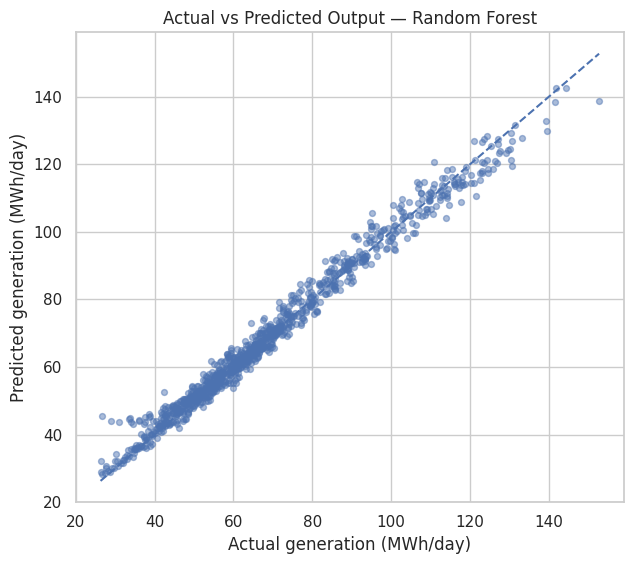

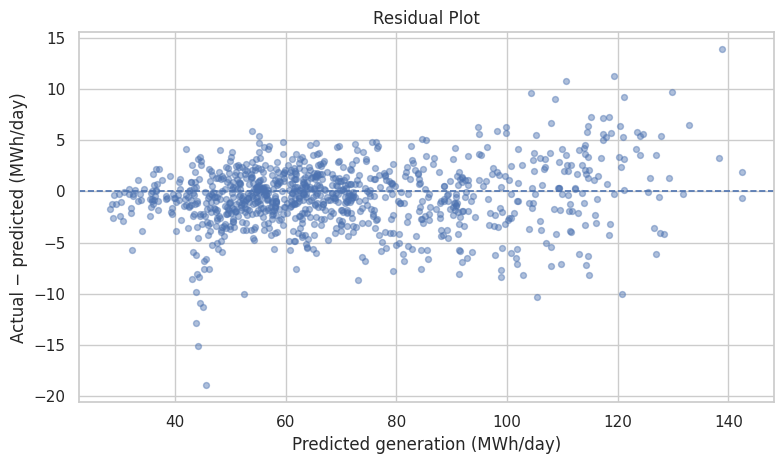

In [10]:
best_name = model_results.iloc[0]["Model"]
best_pred = predictions[best_name]
print("Best candidate on this holdout:", best_name)
print(f"MAE:  {mean_absolute_error(y_test, best_pred):.3f} MWh")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_pred)):.3f} MWh")
print(f"R²:   {r2_score(y_test, best_pred):.4f}")

lo = min(float(y_test.min()), float(np.min(best_pred)))
hi = max(float(y_test.max()), float(np.max(best_pred)))
plt.figure(figsize=(6.5, 5.8))
plt.scatter(y_test, best_pred, alpha=.48, s=18)
plt.plot([lo, hi], [lo, hi], "--", linewidth=1.5)
plt.title(f"Actual vs Predicted Output — {best_name}")
plt.xlabel("Actual generation (MWh/day)")
plt.ylabel("Predicted generation (MWh/day)")
plt.tight_layout()
plt.show()

residuals = y_test.to_numpy() - best_pred
plt.figure(figsize=(8, 4.8))
plt.scatter(best_pred, residuals, alpha=.45, s=18)
plt.axhline(0, linestyle="--", linewidth=1.2)
plt.title("Residual Plot")
plt.xlabel("Predicted generation (MWh/day)")
plt.ylabel("Actual − predicted (MWh/day)")
plt.tight_layout()
plt.show()

## 11. Feature importance and model interpretation
Random Forest feature importance is used as a descriptive diagnostic. It is not a causal ranking and can distribute importance among correlated predictors. Any maintenance or investment action should be supported by engineering checks and measured plant data.

,feature,importance
2,solar_irradiance_kwh_m2_day,0.4221
0,installed_capacity_mw,0.1529
7,panel_cleanliness_index,0.1409
18,district_Jodhpur,0.1159
14,site_Jodhpur Sun Array,0.1105
19,district_Udaipur,0.0126
15,site_Udaipur Solar Station,0.0112
13,site_Jaipur Solar Field,0.0107
17,district_Jaipur,0.0095
1,temperature_c,0.0028


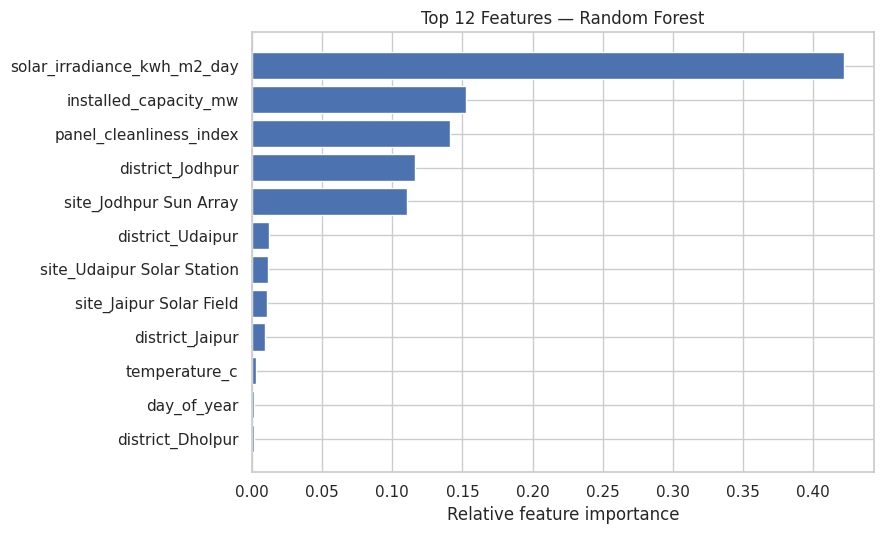

In [11]:
rf_pipeline = trained_models["Random Forest"]
feature_names = rf_pipeline.named_steps["preprocess"].get_feature_names_out()
importances = rf_pipeline.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({"feature": feature_names, "importance": importances})
importance_df["feature"] = importance_df["feature"].str.replace("numeric__", "", regex=False).str.replace("categorical__", "", regex=False)
importance_df = importance_df.sort_values("importance", ascending=False)
display(importance_df.head(12).round(4))
plt.figure(figsize=(9, 5.5))
plot_imp = importance_df.head(12).sort_values("importance")
plt.barh(plot_imp["feature"], plot_imp["importance"])
plt.title("Top 12 Features — Random Forest")
plt.xlabel("Relative feature importance")
plt.tight_layout()
plt.show()

## 12. Findings, recommendations and limitations

### Dataset-level findings
- The synthetic dataset contains four illustrative sites and daily observations from 2022 through 2024.
- Generation varies with solar resource, installed capacity, cleanliness and operational availability by construction.
- Site totals should be read alongside installed capacity; the largest total is not necessarily the most efficient asset.
- The later-period model evaluation provides a more realistic temporal check than a fully random split, but only within the same simulated data-generating process.

### Practical recommendations for a real deployment
1. Replace the CSV with quality-controlled, measured plant and weather data.
2. Compare capacity-normalised yield and uptime rather than total energy alone.
3. Record maintenance and panel-cleaning events consistently.
4. Validate forecasts using rolling-origin/time-series evaluation and compare with simple baselines.
5. Monitor forecast error by site and season before operational adoption.

### Limitations
The dataset is synthetic, weather and generation relationships are simplified, site labels are illustrative, and the model cannot establish causal effects. No energy-cost, emissions, or grid-dispatch conclusions should be made from this dataset alone.

## Reproducibility checklist
- [ ] Keep the CSV and notebook in the same directory.
- [ ] Install `requirements.txt` in the same Python environment.
- [ ] Restart the kernel and run all cells from top to bottom.
- [ ] Review charts, model metrics and any package warnings.
- [ ] Replace synthetic data with validated observations before making real-world claims.

**End of notebook — Aarya Saxena | Roll No. 24202803**